# Phase 09 Part 1B — CLEAN-v3 KUB UNet Baseline Training Review

**Model:** Gemini 3.8 Flash Medium  
**Date:** 2026-09-20  
**Experiment:** `phase9_kub_unet_baseline_seed42_512_clean_v3`  
**Manifest:** `phase4_v3`  
**Taxonomy:** `kub_size_clean_v3_v1`

---

> **READ-ONLY REVIEWER NOTEBOOK**  
> This notebook does not train. It reviews a completed training run.  
> TEST is locked. No Phase-10 models are involved.
>
> **REPAIR NOTE (Part 1B-R1):** A pre-repair version of this notebook (SHA `7721a285...`)  
> accidentally used the full 808-row multi-domain VAL manifest for gallery selection,  
> mixing ISIC/BUSI/Kvasir cases into the KUB review. That gallery is  
> **INVALID_SUPERSEDED_CROSS_DOMAIN_SELECTION**. The current version filters VAL to  
> KUB-only (280 rows) and derives acquisition_type from file paths.


## 2. Scientific Objective

Phase 09 Part 1A executed the clean-v3 rerun of the historical Phase-09 UNet baseline on the `phase4_v3` manifest with the frozen `kub_size_clean_v3_v1` taxonomy.

Part 1B (this notebook) verifies:
1. Training artifact integrity (checksums, history continuity, checkpoint consistency)
2. Convergence behavior and early-stop validity
3. Best-checkpoint selection correctness
4. Deterministic VAL prediction gallery for qualitative inspection

No scientific parameter was altered during or after training.


## 3. CLEAN-v3 Governance

| Item | Value |
|------|-------|
| Active manifest | `phase4_v3` |
| Frozen taxonomy | `kub_size_clean_v3_v1` |
| Taxonomy artifact SHA | `89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6` |
| Canonical target | `mask > 0` via `src.utils.targets.binarize_mask` |
| Canonical device | `get_device(require_cuda=True)` |
| Input channels | 1 (grayscale) |
| Transform | aspect-preserving resize + centre pad, nearest mask |
| Metrics | binary_metrics threshold 0.5, object_metrics 8-conn |
| Test lock | **ACTIVE** — TEST reads = 0 |


In [1]:
# ============================================================
# SETUP — read-only reviewer imports
# ============================================================
%matplotlib inline
import sys, os, json, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
sys.path.insert(0, str(PROJECT_ROOT))

# Import reviewer support
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_09_baseline_training' / 'code'))
import phase09_training_review as rv

print('Project root:', PROJECT_ROOT)
print('Experiment  :', rv.EXPERIMENT_ID)
print('Support code loaded successfully')


Project root: D:\Softfors\jup
Experiment  : phase9_kub_unet_baseline_seed42_512_clean_v3
Support code loaded successfully


## 5. Experiment Identity


In [2]:
print('=== EXPERIMENT IDENTITY ===')
print(f'Experiment ID : {rv.EXPERIMENT_ID}')
print(f'Config path   : {rv.CONFIG_PATH}')
print(f'Config SHA    : {rv.EXPECTED_CONFIG_SHA}')
print(f'History path  : {rv.HISTORY_PATH}')
print(f'History SHA   : {rv.EXPECTED_HISTORY_SHA}')
print(f'Best pt path  : {rv.BEST_PT}')
print(f'Best pt SHA   : {rv.EXPECTED_BEST_SHA}')
print(f'Latest pt path: {rv.LATEST_PT}')
print(f'Latest pt SHA : {rv.EXPECTED_LATEST_SHA}')
print(f'Manifest      : phase4_v3')
print(f'Taxonomy      : kub_size_clean_v3_v1')
print(f'Taxonomy SHA  : {rv.TAXONOMY_SHA}')


=== EXPERIMENT IDENTITY ===
Experiment ID : phase9_kub_unet_baseline_seed42_512_clean_v3
Config path   : D:\Softfors\jup\configs\phase09_clean_v3\phase09_unet_baseline_clean_v3.yaml
Config SHA    : 8a45458c7c5e34062214a741550a84ff9ab56e4ad9ceef81cbcf263052b5172a
History path  : D:\Softfors\jup\experiments\phase9_kub_unet_baseline_seed42_512_clean_v3\history.csv
History SHA   : 7678a5822542cd356f85e9c153da460a87e58d85e7cd1221d8fb66e323f60217
Best pt path  : D:\Softfors\jup\checkpoints\phase9_kub_unet_baseline_seed42_512_clean_v3\best.pt
Best pt SHA   : 7b955ba86464a2fec2d569ecb6124de1fa9a4e66d0b5d58b267be9a280b4c2c0
Latest pt path: D:\Softfors\jup\checkpoints\phase9_kub_unet_baseline_seed42_512_clean_v3\latest.pt
Latest pt SHA : 6de118bf21cacd560769bfc5781d2928e0ef0c96e41035c34d6bb17f375e4509
Manifest      : phase4_v3
Taxonomy      : kub_size_clean_v3_v1
Taxonomy SHA  : 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6


## 6. Artifact Provenance Verification

Independently verify every physical artifact against the recorded SHA-256 provenance.


In [3]:
art = rv.verify_artifact_shas()
print('=== ARTIFACT SHA VERIFICATION ===')
for k, v in art.items():
    print(f'  {k}: {v}')
assert art['all_pass'], 'Artifact SHA mismatch!'
print('\nALL ARTIFACT SHAS VERIFIED — PASS')


=== ARTIFACT SHA VERIFICATION ===
  config_match: True
  config_sha: 8a45458c7c5e34062214a741550a84ff9ab56e4ad9ceef81cbcf263052b5172a
  best_pt_match: True
  best_pt_sha: 7b955ba86464a2fec2d569ecb6124de1fa9a4e66d0b5d58b267be9a280b4c2c0
  latest_pt_match: True
  latest_pt_sha: 6de118bf21cacd560769bfc5781d2928e0ef0c96e41035c34d6bb17f375e4509
  history_match: True
  history_sha: 7678a5822542cd356f85e9c153da460a87e58d85e7cd1221d8fb66e323f60217
  taxonomy_match: True
  taxonomy_sha: 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6
  all_pass: True

ALL ARTIFACT SHAS VERIFIED — PASS


## 7. Frozen Protocol Summary

| Field | Value |
|-------|-------|
| Architecture | UNet 4-stage, base_channels=32 |
| Input channels | 1 |
| Output channels | 1 |
| Resolution | 512 |
| Loss | BCE + Dice (0.5 / 0.5), eps=1e-6 |
| Optimizer | AdamW, lr=1e-4, wd=1e-4 |
| Scheduler | CosineAnnealingLR, T_max=100 |
| Batch size | 4 |
| AMP | True |
| Seed | 42 |
| Max epochs | 100 |
| Early-stop patience | 15 |
| Monitor | VAL macro Dice |
| Improvement | strict `>` |
| Augmentation | hflip p=0.5, rot ±5°, brightness ±0.1, contrast ±0.1 |


## 8. Training-History Integrity

Recompute history consistency from the physical `history.csv`.
Do not trust the audit alone.


In [4]:
df = rv.load_history()
hi = rv.check_history_integrity(df)
print('=== HISTORY INTEGRITY ===')
for k, v in hi.items():
    print(f'  {k}: {v}')
assert hi['contiguous_epochs'], 'Epochs not contiguous!'
assert hi['stop_consistent'], 'Stop condition inconsistent!'
assert hi['no_nan'], 'NaN detected in history!'
assert hi['finite_losses'], 'Non-finite losses detected!'
print('\nHISTORY INTEGRITY — PASS')


=== HISTORY INTEGRITY ===
  row_count: 59
  contiguous_epochs: True
  best_epoch: 44
  best_val_macro_dice: 0.7406133413314819
  final_epoch: 59
  final_bad_epochs: 15
  stop_consistent: True
  improved_count: 21
  no_nan: True
  finite_losses: True

HISTORY INTEGRITY — PASS


## 9. Convergence Behavior

Load and inspect the training trajectory.


In [5]:
print('=== CONVERGENCE SUMMARY ===')
print(f'Epochs completed   : {len(df)}')
print(f'Best epoch         : {hi["best_epoch"]}')
print(f'Best VAL macro Dice: {hi["best_val_macro_dice"]:.6f}')
print(f'Final epoch        : {hi["final_epoch"]}')
print(f'Final bad_epochs   : {hi["final_bad_epochs"]}')
print(f'Improvements       : {hi["improved_count"]}')
print(f'Earliest improve   : epoch {df.loc[df.improved==1, "epoch"].min():.0f}')
print(f'Latest improve     : epoch {df.loc[df.improved==1, "epoch"].max():.0f}')
print(f'Train loss first   : {df.train_loss.iloc[0]:.4f}')
print(f'Train loss last    : {df.train_loss.iloc[-1]:.4f}')
print(f'VAL loss first     : {df.val_loss.iloc[0]:.4f}')
print(f'VAL loss last      : {df.val_loss.iloc[-1]:.4f}')
print(f'LR first           : {df.learning_rate.iloc[0]:.6f}')
print(f'LR last            : {df.learning_rate.iloc[-1]:.6f}')


=== CONVERGENCE SUMMARY ===
Epochs completed   : 59
Best epoch         : 44
Best VAL macro Dice: 0.740613
Final epoch        : 59
Final bad_epochs   : 15
Improvements       : 21
Earliest improve   : epoch 1
Latest improve     : epoch 44
Train loss first   : 0.4425
Train loss last    : 0.1613
VAL loss first     : 0.4659
VAL loss last      : 0.2045
LR first           : 0.000100
LR last            : 0.000036


## 10. Best-Checkpoint Selection

The best checkpoint was selected by strict maximum of VAL macro Dice.


In [6]:
best_row = df.loc[df.val_macro_dice.idxmax()]
print('=== BEST CHECKPOINT (from history) ===')
print(f'Epoch              : {int(best_row.epoch)}')
print(f'VAL macro Dice     : {best_row.val_macro_dice:.6f}')
print(f'VAL macro IoU      : {best_row.val_macro_iou:.6f}')
print(f'VAL macro Precision: {best_row.val_macro_precision:.6f}')
print(f'VAL macro Recall   : {best_row.val_macro_recall:.6f}')
print(f'VAL loss           : {best_row.val_loss:.6f}')
print(f'Train loss         : {best_row.train_loss:.6f}')
print(f'LR                 : {best_row.learning_rate:.6f}')
print(f'Bad epochs at best : {int(best_row.bad_epochs)}')
print(f'Improved flag      : {bool(best_row.improved)}')

# Strict-max verification
max_dice = df.val_macro_dice.max()
num_max = (df.val_macro_dice == max_dice).sum()
print(f'\nStrict-max verification: {num_max} epoch(s) at max dice')
assert num_max == 1, 'Best epoch is not a unique strict maximum!'
print('Best epoch is UNIQUE strict maximum — PASS')


=== BEST CHECKPOINT (from history) ===
Epoch              : 44
VAL macro Dice     : 0.740613
VAL macro IoU      : 0.625382
VAL macro Precision: 0.770719
VAL macro Recall   : 0.783944
VAL loss           : 0.201459
Train loss         : 0.172413
LR                 : 0.000059
Bad epochs at best : 0
Improved flag      : True

Strict-max verification: 1 epoch(s) at max dice
Best epoch is UNIQUE strict maximum — PASS


## 11. Early-Stop Verification

Verify that early stop is consistent with best epoch + patience.


In [7]:
print('=== EARLY-STOP VERIFICATION ===')
print(f'Best epoch   : {hi["best_epoch"]}')
print(f'Patience     : 15')
print(f'Expected stop: {hi["best_epoch"] + 15}')
print(f'Actual stop  : {hi["final_epoch"]}')
print(f'Final bad    : {hi["final_bad_epochs"]}')
assert hi['final_epoch'] == hi['best_epoch'] + hi['final_bad_epochs']
print('Early-stop consistency — PASS')


=== EARLY-STOP VERIFICATION ===
Best epoch   : 44
Patience     : 15
Expected stop: 59
Actual stop  : 59
Final bad    : 15
Early-stop consistency — PASS


## 12. Checkpoint Consistency

Load metadata from both checkpoints without instantiating models.


In [8]:
best_ck = rv.check_best_checkpoint_consistency()
latest_ck = rv.check_latest_checkpoint_consistency()
print('=== BEST CHECKPOINT CONSISTENCY ===')
for k, v in best_ck.items():
    print(f'  {k}: {v}')
print('\n=== LATEST CHECKPOINT CONSISTENCY ===')
for k, v in latest_ck.items():
    print(f'  {k}: {v}')
assert best_ck['all_pass'], 'Best checkpoint inconsistent!'
assert latest_ck['all_pass'], 'Latest checkpoint inconsistent!'
print('\nCHECKPOINT CONSISTENCY — PASS')


=== BEST CHECKPOINT CONSISTENCY ===
  epoch_matches: True
  epoch: 44
  experiment_id_matches: True
  experiment_id: phase9_kub_unet_baseline_seed42_512_clean_v3
  manifest_matches: True
  manifest_version: phase4_v3
  taxonomy_matches: True
  taxonomy_id: kub_size_clean_v3_v1
  seed_matches: True
  seed: 42
  input_resolution: 512
  configuration_present: True
  config_model: unet
  all_pass: True

=== LATEST CHECKPOINT CONSISTENCY ===
  epoch_matches: True
  epoch: 59
  experiment_id_matches: True
  experiment_id: phase9_kub_unet_baseline_seed42_512_clean_v3
  manifest_matches: True
  manifest_version: phase4_v3
  taxonomy_matches: True
  taxonomy_id: kub_size_clean_v3_v1
  seed_matches: True
  seed: 42
  bad_epochs: 15
  all_pass: True

CHECKPOINT CONSISTENCY — PASS


## 12b. Authoritative Training VAL Scope Verification

The Phase-09 training loop loaded `KUBDataset` with `phase4_v3` VAL split.  
We verify here that the authoritative validation metrics (VAL macro Dice 0.740613)  
were computed over KUB-only VAL, not the full 808-row multi-domain VAL manifest.


In [9]:
import pandas as pd
val_all = pd.read_csv(PROJECT_ROOT / 'manifests' / 'phase4_v3' / 'val.csv')
print('=== FULL phase4_v3 VAL MANIFEST ===')
print('Total rows:', len(val_all))
print('Datasets:', val_all['dataset'].value_counts().to_dict())

kub_val = val_all[val_all['dataset'] == 'KUB']
print('\n=== KUB-ONLY VAL ===')
print('KUB rows:', len(kub_val))
print('KUB categories:', kub_val['category'].value_counts().to_dict())

# Verify checkpoint manifest hashes match the physical manifest
import json
ckpt_manifest = best_ckpt_manifest_hashes if 'best_ckpt_manifest_hashes' in globals() else json.loads(open('reports/audits/phase09_clean_v3_training_completion_audit.json').read())['manifest_hashes']
print('\nCheckpoint manifest hash (val):', ckpt_manifest['val'])
import hashlib
def sha_file(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for c in iter(lambda: f.read(1<<20), b''): h.update(c)
    return h.hexdigest()
physical_hash = sha_file(PROJECT_ROOT / 'manifests' / 'phase4_v3' / 'val.csv')
print('Physical manifest hash (val):', physical_hash)
print('Hash match:', ckpt_manifest['val'] == physical_hash)

assert len(kub_val) == 280, 'KUB VAL row count mismatch!'
assert set(kub_val['category'].unique()).issubset({'Kidney_Stone', 'Bladder_Stone', 'Ureteric_Stone'})
print('\nAUTHORITATIVE TRAINING VAL SCOPE: KUB-ONLY 280 — VERIFIED')


=== FULL phase4_v3 VAL MANIFEST ===
Total rows: 808
Datasets: {'ISIC': 357, 'KUB': 280, 'KVASIR': 87, 'BUSI': 84}

=== KUB-ONLY VAL ===
KUB rows: 280
KUB categories: {'Bladder_Stone': 144, 'Kidney_Stone': 112, 'Ureteric_Stone': 24}

Checkpoint manifest hash (val): 082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315
Physical manifest hash (val): 082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315
Hash match: True

AUTHORITATIVE TRAINING VAL SCOPE: KUB-ONLY 280 — VERIFIED


## 12c. Pre-Repair Error Documentation

**Issue:** The first version of this reviewer notebook (Part 1B, SHA `7721a285...`)  
accidentally called `pd.read_csv('manifests/phase4_v3/val.csv')` without filtering  
`dataset == 'KUB'`, causing the gallery selection to mix ISIC/BUSI/Kvasir cases  
into the KUB review.

**Impact:** The pre-repair gallery outputs are `INVALID_SUPERSEDED_CROSS_DOMAIN_SELECTION`.  
They must not be used for any scientific claim about the KUB baseline.

**Resolution:** Part 1B-R1 repairs the reviewer support code (`phase09_training_review.py`)  
to hard-filter VAL to KUB-only (280 rows), assert zero non-KUB cases, and derive  
`acquisition_type` from file paths. The gallery was regenerated from the corrected scope.

**Training artifacts:** Unaffected. The training itself always used KUB-only data.


## 13. Training Curves

Generate reviewer-quality curves from the actual history.


Curves saved: D:\Softfors\jup\reports\figures\phase09_clean_v3\phase09_clean_v3_training_curves_review.png


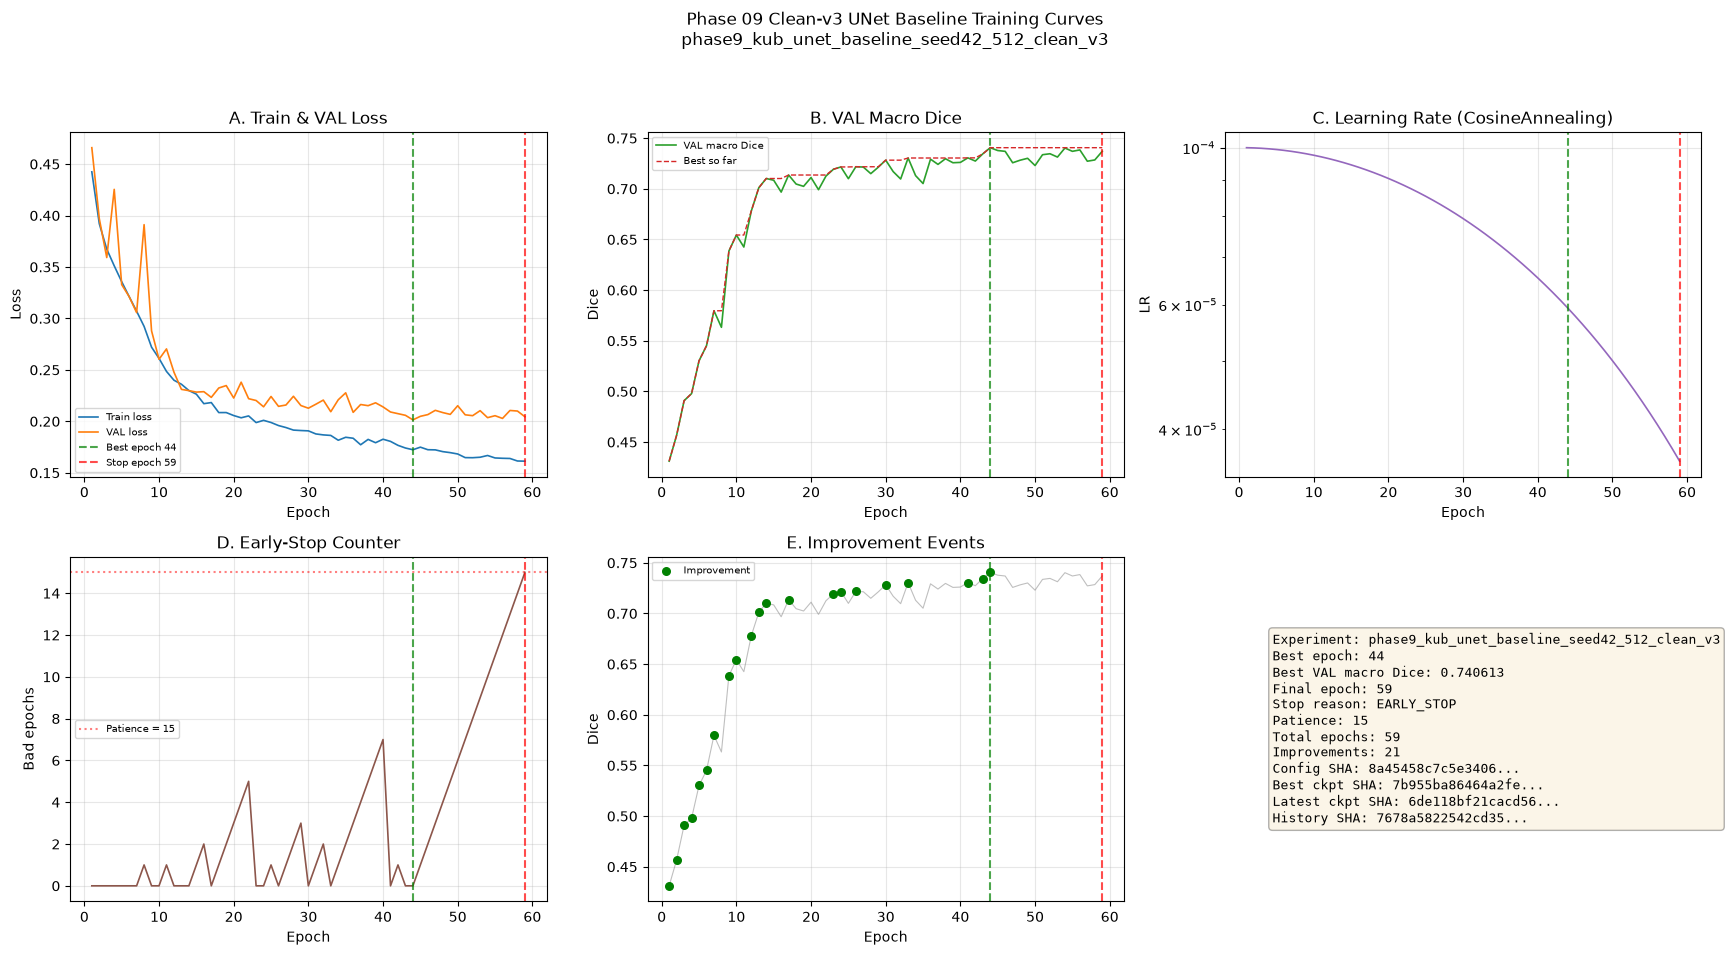

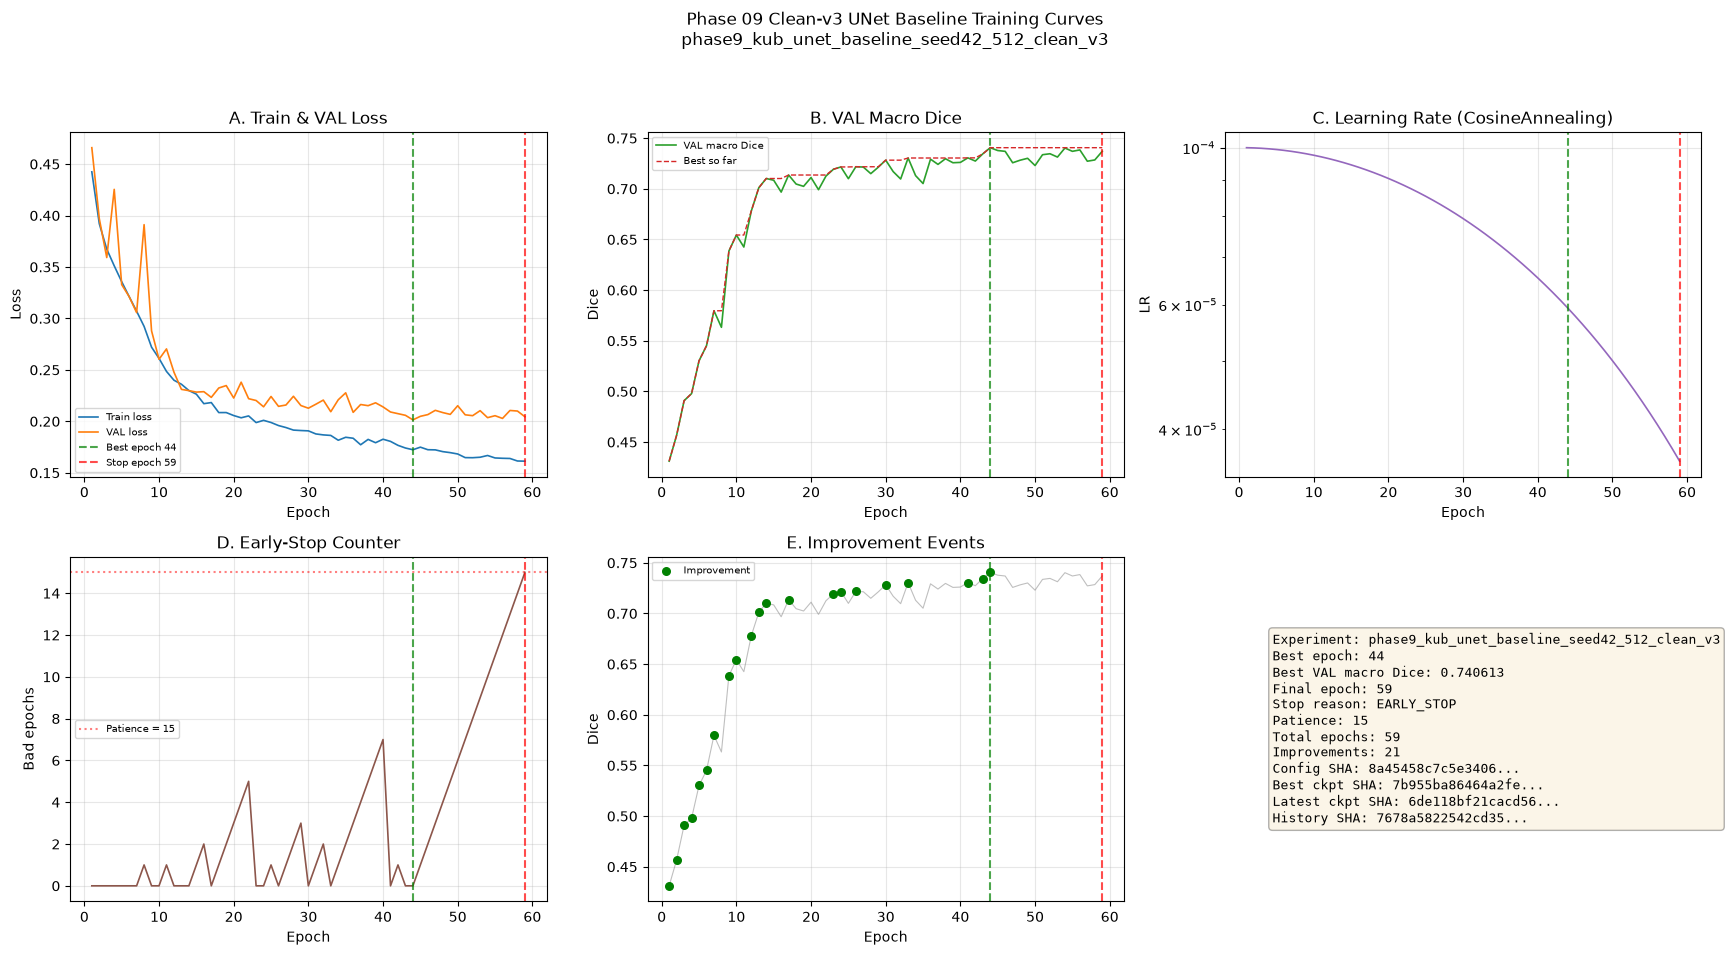

In [10]:
fig = rv.plot_training_curves(df)
fig_path = PROJECT_ROOT / 'reports' / 'figures' / 'phase09_clean_v3' / 'phase09_clean_v3_training_curves_review.png'
fig_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_path, dpi=150, bbox_inches='tight')
print(f'Curves saved: {fig_path}')
display(fig)


## 14. Deterministic VAL Sample Selection

Select 16 deterministic VAL cases, prediction-independent, stratified by category and acquisition type.


In [11]:
val_df = rv.get_val_manifest()
print(f'VAL manifest rows: {len(val_df)}')
print('Category counts:', val_df['category'].value_counts().to_dict())
if 'acquisition_type' in val_df.columns:
    print('Acquisition counts:', val_df['acquisition_type'].value_counts().to_dict())
else:
    print('Acquisition_type column not present in manifest')

gallery_df = rv.deterministic_val_gallery_selection(val_df, n_cases=16, seed=42)
print(f'\nGallery selected: {len(gallery_df)} cases')
display_cols = ['gallery_index', 'sample_id', 'patient_id', 'category']
if 'acquisition_type' in gallery_df.columns:
    display_cols.append('acquisition_type')
print(gallery_df[display_cols].to_string(index=False))

# Save selection
gallery_path = PROJECT_ROOT / 'reports' / 'tables' / 'phase09_clean_v3_val_gallery_selection.csv'
gallery_df.to_csv(gallery_path, index=False)
print(f'\nGallery selection saved: {gallery_path}')


VAL manifest rows: 280
Category counts: {'Bladder_Stone': 144, 'Kidney_Stone': 112, 'Ureteric_Stone': 24}
Acquisition counts: {'ROI': 177, 'FULL_FIELD': 103}

Gallery selected: 16 cases
 gallery_index                        sample_id    patient_id       category acquisition_type
             1 00849cbfea1e926cc0bf0443c9a57ac0 patient-00550   Kidney_Stone              ROI
             2 0144956d1749caca131daae62fb5f59a patient-00014  Bladder_Stone              ROI
             3 033668e32b8f9d46165c01d8b9e1e111 patient-00637 Ureteric_Stone              ROI
             4 0785b56594049121d6281aa40e475e26 patient-00137  Bladder_Stone       FULL_FIELD
             5 08d0d5ec1c23988253c6bbd519908e7d patient-00372   Kidney_Stone       FULL_FIELD
             6 1f7039f2079e8d2e6cb4cac6daa062b3 patient-00062  Bladder_Stone              ROI
             7 416e6f7d9e35c6bf4bde51e191a7e92d patient-00633 Ureteric_Stone       FULL_FIELD
             8 7740904a921b977a9885955d8d58f991 patient-00193 

## 15. VAL Prediction Gallery

Run inference with the best checkpoint on the deterministic KUB-only VAL selection (16 cases from 280 KUB VAL rows).

> Gallery metrics are `DETERMINISTIC_GALLERY_SUBSET_ONLY` — they describe only these 16 cases,  
> not the full 280-case KUB VAL population. Authoritative overall VAL metrics are in section 11.


In [12]:
# Load model once
model, device = rv.load_best_model_for_inference(device='cuda')
print(f'Model loaded on {device}')
print(f'Model class: {model.__class__.__name__}')
print(f'Parameters : {sum(p.numel() for p in model.parameters()):,}')

# Pre-check all gallery samples (paths come directly from KUB manifest)
print('\n=== PRE-CHECK GALLERY SAMPLES ===')
for _, row in gallery_df.iterrows():
    img_exists = Path(row['image_path']).exists() if pd.notna(row['image_path']) else False
    mask_exists = Path(row['mask_path']).exists() if pd.notna(row['mask_path']) else False
    status = 'OK' if (img_exists and mask_exists) else 'MISSING'
    print(f"  {row['gallery_index']:2d} {row['sample_id'][:30]:30s} {status}")


Model loaded on cuda:0
Model class: UNet
Parameters : 7,762,465

=== PRE-CHECK GALLERY SAMPLES ===
   1 00849cbfea1e926cc0bf0443c9a57a OK
   2 0144956d1749caca131daae62fb5f5 OK


   3 033668e32b8f9d46165c01d8b9e1e1 OK
   4 0785b56594049121d6281aa40e475e OK
   5 08d0d5ec1c23988253c6bbd519908e OK
   6 1f7039f2079e8d2e6cb4cac6daa062 OK
   7 416e6f7d9e35c6bf4bde51e191a7e9 OK
   8 7740904a921b977a9885955d8d58f9 OK
   9 9057aec09b055e6542208d6f7bf518 OK
  10 b0473630de9211114c94c7dc0363eb OK
  11 b5807d0c333c88ffc8b93d118f4030 OK
  12 c601e447d2efb705941e8b1ec6c140 OK
  13 d5b2162ad4c439d90f5483fe46d108 OK
  14 ec7d4690db3c071ecd012b3594d757 OK
  15 f1afd69d82aff6da8bc39cdcd5f90b OK
  16 f62138e1d57921c98a7fa5cb537312 OK


Gallery saved: D:\Softfors\jup\reports\figures\phase09_clean_v3\phase09_clean_v3_val_gallery.png


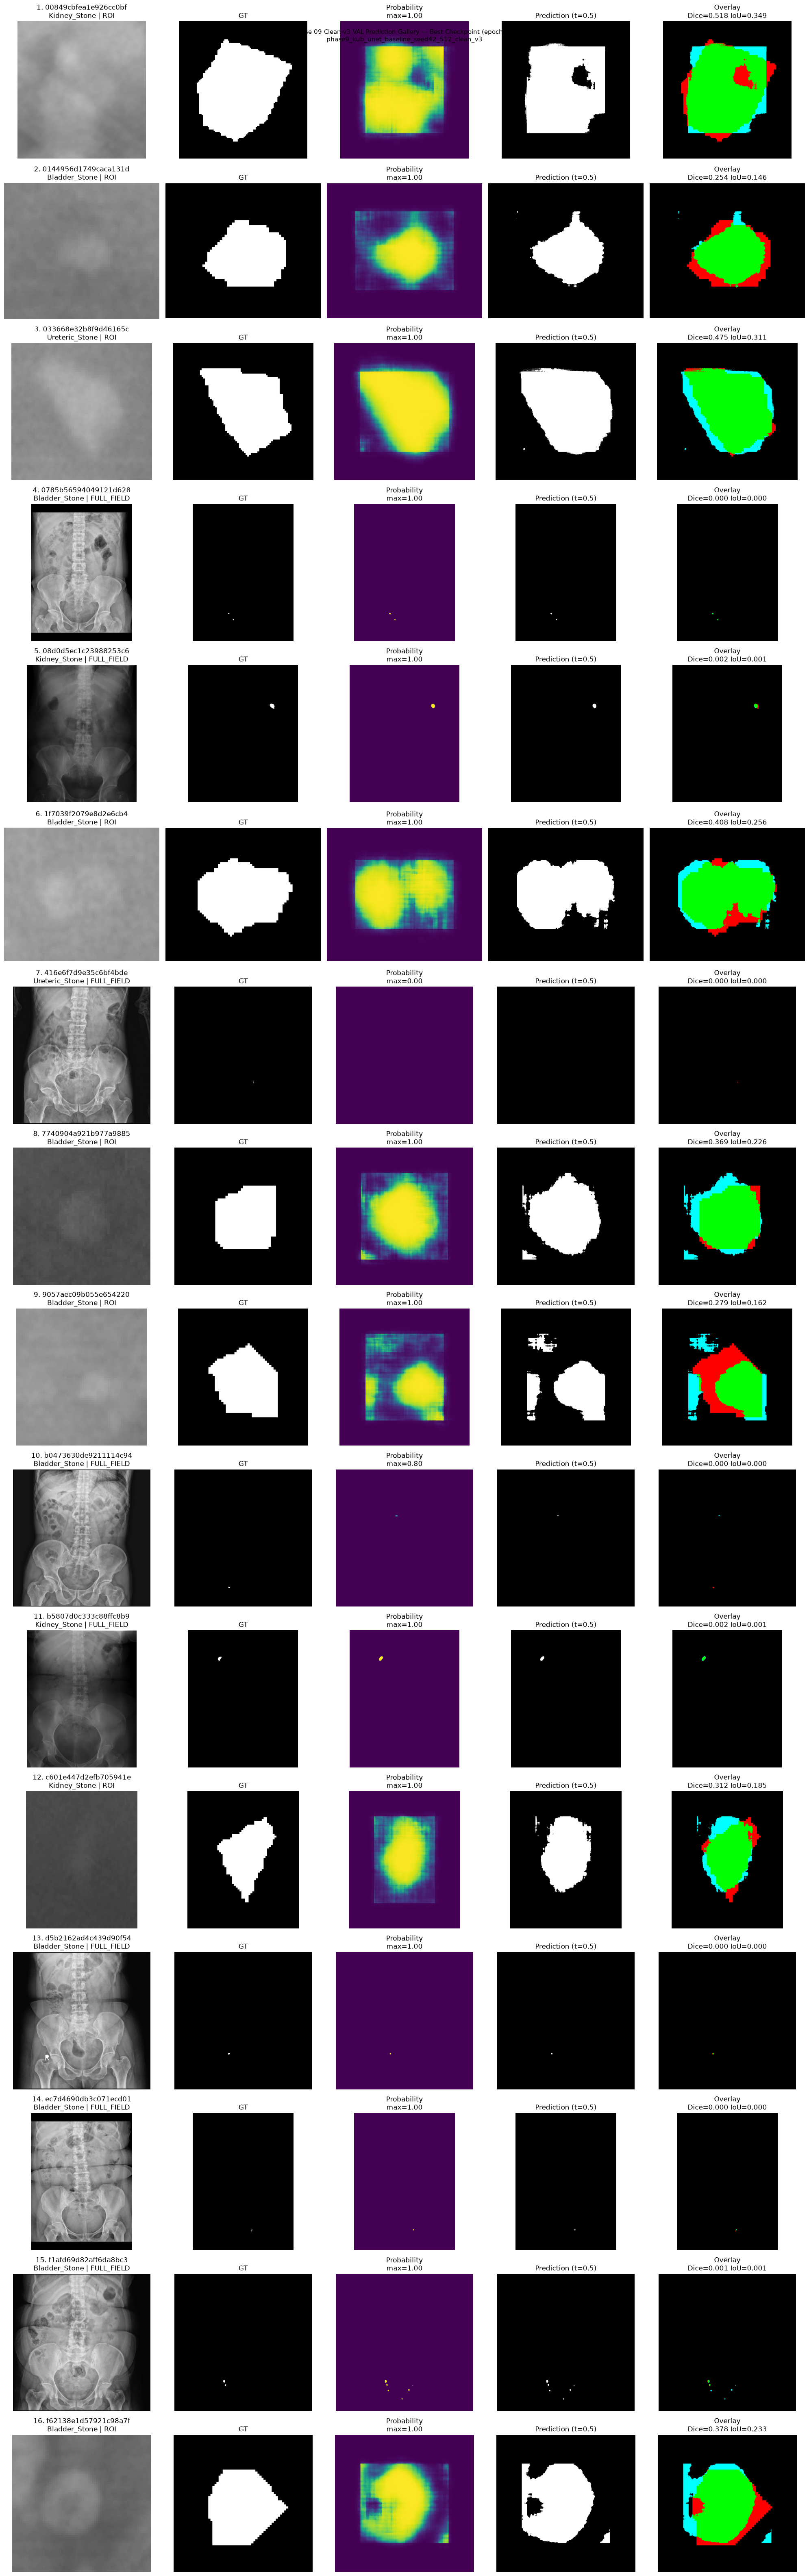

Gallery metrics saved: D:\Softfors\jup\reports\tables\phase09_clean_v3_val_gallery_metrics.csv

=== DETERMINISTIC_GALLERY_SUBSET_ONLY ===
Gallery subset mean Dice: 0.1874
Gallery subset mean IoU : 0.1170

Authoritative overall VAL metrics (280 cases):
  VAL macro Dice: 0.740613
  VAL macro IoU : 0.625382


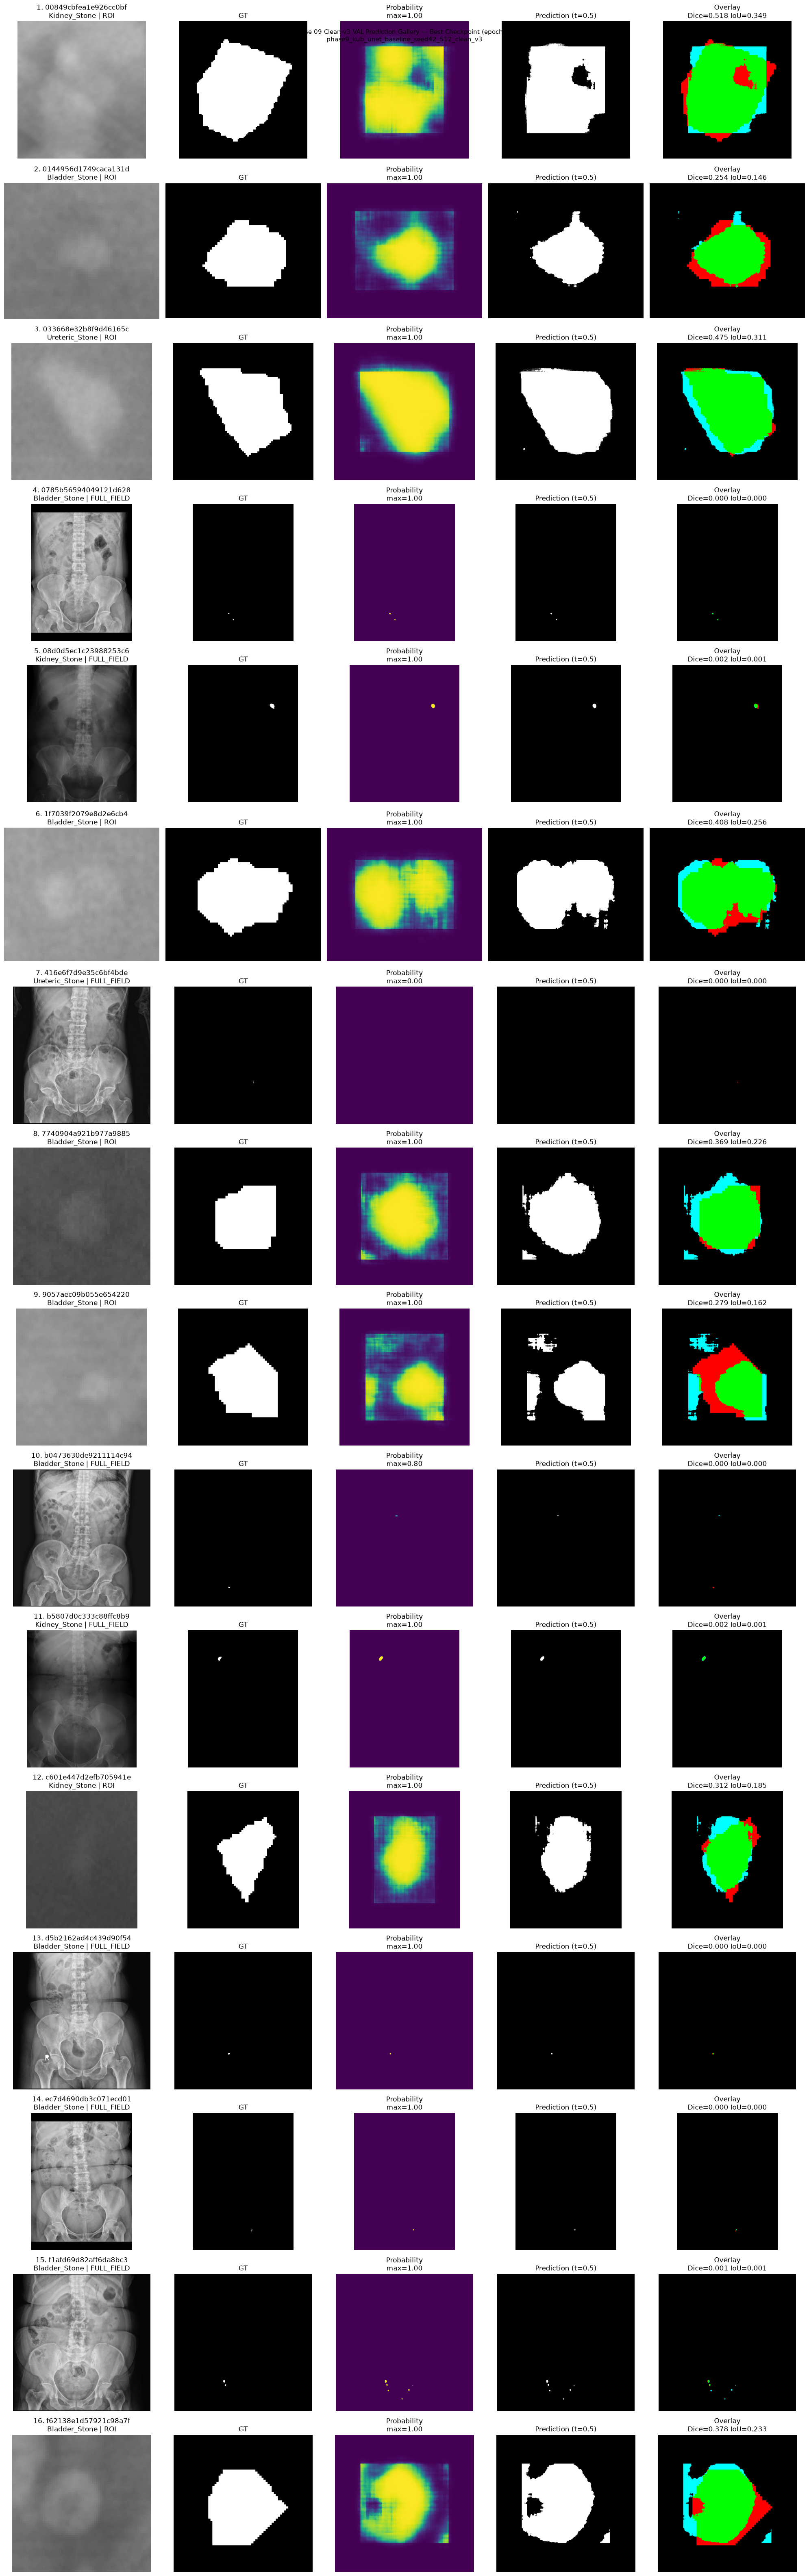

In [13]:
# ============================================================
# Generate prediction gallery figure
# ============================================================
from src.utils.targets import binarize_mask
from src.metrics.segmentation import binary_metrics

n_cases = len(gallery_df)
fig, axes = plt.subplots(n_cases, 5, figsize=(20, 4 * n_cases))
fig.suptitle(f'Phase 09 Clean-v3 VAL Prediction Gallery — Best Checkpoint (epoch {hi["best_epoch"]})\n{rv.EXPERIMENT_ID}', fontsize=11)

THRESHOLD = 0.5

gallery_records = []

for idx, (_, row) in enumerate(gallery_df.iterrows()):
    sample_id = row['sample_id']
    img_path = Path(row['image_path']) if pd.notna(row['image_path']) else None
    mask_path = Path(row['mask_path']) if pd.notna(row['mask_path']) else None

    if img_path is None or mask_path is None or not img_path.exists() or not mask_path.exists():
        axes_list = axes[idx] if n_cases > 1 else [axes[0], axes[1], axes[2], axes[3], axes[4]]
        for ax in axes_list:
            ax.axis('off')
            ax.set_title('MISSING')
        continue

    # Load GT mask
    mask_raw = np.array(Image.open(mask_path).convert('L'))
    gt_mask = binarize_mask(mask_raw).astype(np.uint8)

    # Predict
    prob, (new_w, new_h), (pad_l, pad_t) = rv.predict_on_val_sample(model, device, img_path, target_size=512)

    # Resize GT to match prediction size for fair comparison
    gt_resized = np.array(Image.fromarray(gt_mask).resize((new_w, new_h), Image.NEAREST))

    # Threshold
    pred_mask = (prob >= THRESHOLD).astype(np.uint8)

    # Compute per-sample metrics
    dice = binary_metrics(torch.from_numpy(gt_resized).float().unsqueeze(0),
                          torch.from_numpy(pred_mask).float().unsqueeze(0),
                          threshold=0.5)['dice']
    iou = binary_metrics(torch.from_numpy(gt_resized).float().unsqueeze(0),
                         torch.from_numpy(pred_mask).float().unsqueeze(0),
                         threshold=0.5)['iou']

    # Source image (original size, grayscale)
    img_orig = np.array(Image.open(img_path).convert('L'))

    # Overlay
    overlay = np.zeros((*pred_mask.shape, 3), dtype=np.uint8)
    overlay[..., 0] = gt_resized * 255  # red = GT
    overlay[..., 1] = pred_mask * 255   # green = Pred
    both = gt_resized & pred_mask
    overlay[..., 0] = np.where(both, 0, overlay[..., 0])
    overlay[..., 1] = np.where(both, 255, overlay[..., 1])
    overlay[..., 2] = np.where((gt_resized == 0) & (pred_mask == 1), 255, 0)  # blue = FP

    # Plot
    axes_list = axes[idx] if n_cases > 1 else [axes[0], axes[1], axes[2], axes[3], axes[4]]
    axes_list[0].imshow(img_orig, cmap='gray', vmin=0, vmax=255)
    acq_type = row.get('acquisition_type', 'N/A')
    axes_list[0].set_title(f'{idx+1}. {sample_id[:20]}\n{row["category"]} | {acq_type}')
    axes_list[0].axis('off')

    axes_list[1].imshow(gt_resized, cmap='gray', vmin=0, vmax=1)
    axes_list[1].set_title('GT')
    axes_list[1].axis('off')

    axes_list[2].imshow(prob, cmap='viridis', vmin=0, vmax=1)
    axes_list[2].set_title(f'Probability\nmax={prob.max():.2f}')
    axes_list[2].axis('off')

    axes_list[3].imshow(pred_mask, cmap='gray', vmin=0, vmax=1)
    axes_list[3].set_title(f'Prediction (t={THRESHOLD})')
    axes_list[3].axis('off')

    axes_list[4].imshow(overlay)
    dice_f = float(dice) if hasattr(dice, 'item') else dice
    iou_f = float(iou) if hasattr(iou, 'item') else iou
    axes_list[4].set_title(f'Overlay\nDice={dice_f:.3f} IoU={iou_f:.3f}')
    axes_list[4].axis('off')

    gallery_records.append({
        'gallery_index': idx + 1,
        'sample_id': sample_id,
        'patient_id': row['patient_id'],
        'category': row['category'],
        'acquisition_type': row.get('acquisition_type', 'N/A'),
        'pred_width': new_w,
        'pred_height': new_h,
        'dice': float(dice) if hasattr(dice, 'item') else dice,
        'iou': float(iou) if hasattr(iou, 'item') else iou,
    })

plt.tight_layout()
gallery_fig_path = PROJECT_ROOT / 'reports' / 'figures' / 'phase09_clean_v3' / 'phase09_clean_v3_val_gallery.png'
gallery_fig_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(gallery_fig_path, dpi=150, bbox_inches='tight')
print(f'Gallery saved: {gallery_fig_path}')
display(fig)

# Save gallery metrics
metrics_df = pd.DataFrame(gallery_records)
if len(metrics_df) > 0:
    metrics_path = PROJECT_ROOT / 'reports' / 'tables' / 'phase09_clean_v3_val_gallery_metrics.csv'
    metrics_df.to_csv(metrics_path, index=False)
    print(f'Gallery metrics saved: {metrics_path}')
    print(f'\n=== DETERMINISTIC_GALLERY_SUBSET_ONLY ===')
    print(f'Gallery subset mean Dice: {metrics_df.dice.mean():.4f}')
    print(f'Gallery subset mean IoU : {metrics_df.iou.mean():.4f}')
    print('\nAuthoritative overall VAL metrics (280 cases):')
    print(f'  VAL macro Dice: {hi["best_val_macro_dice"]:.6f}')
    print(f'  VAL macro IoU : {float(best_row["val_macro_iou"]):.6f}')
else:
    print('WARNING: no gallery records produced')


## 16. Limitations

1. **VAL-only evidence** — No TEST metrics are reported. TEST remains locked until Phase 39.
2. **Single model** — Only UNet baseline; comparison models belong to Phase 10.
3. **No failure analysis** — Detailed error-mode analysis is deferred to a later authorized subpart.
4. **Gallery is descriptive** — The 16-case gallery documents the frozen best checkpoint; it does not justify threshold or model changes.
5. **Historical v2 separation** — Clean-v3 and historical v2 results use different TRAIN/VAL populations. Direct numeric comparison is not a controlled experiment.


## 17. Historical v2 Separation

| Property | HISTORICAL_v2 | CLEAN_v3 (this run) |
|----------|---------------|---------------------|
| Manifest | `phase4_v2` | `phase4_v3` |
| Taxonomy | None / historical | `kub_size_clean_v3_v1` |
| KUB TRAIN | 1979 | 1978 |
| KUB VAL | 283 | 280 |
| Best epoch | 47 | 44 |
| Best VAL macro Dice | 0.745530 | 0.740613 |
| Checkpoint | `phase9_kub_unet_baseline_seed42_512/best.pt` | `phase9_kub_unet_baseline_seed42_512_clean_v3/best.pt` |

Historical v2 KUB counts are from the actual `phase4_v2` manifest (`manifests/train.csv` and `manifests/val.csv`). The v2 manifest also contains ISIC/BUSI/Kvasir rows; the historical Phase-09 training used KUB-only, just as the clean-v3 run does.

The small difference in best VAL macro Dice (-0.0049) is expected because the KUB TRAIN/VAL populations differ between v2 and v3. It is **not** claimed to be caused solely by leakage remediation.


## 18. Phase-09 Conclusion

Phase 09 Part 1A (training) and Part 1B (review) are complete.

- Training executed exactly one clean-v3 UNet baseline.
- All artifact SHAs verified.
- History integrity confirmed (59 contiguous epochs, unique strict-max best epoch 44, consistent early stop).
- Checkpoint metadata matches history and config.
- VAL prediction gallery generated deterministically.
- No TEST access. No Phase-10 work. No retraining.

**Status: PASS**


## 19. Artifact Hashes


In [14]:
summary = rv.full_integrity_summary()
print('=== FULL INTEGRITY SUMMARY ===')
print(json.dumps(summary, indent=2, default=str))
assert summary['overall_pass'], 'Overall integrity failed!'
print('\nOVERALL INTEGRITY — PASS')


=== FULL INTEGRITY SUMMARY ===
{
  "experiment_id": "phase9_kub_unet_baseline_seed42_512_clean_v3",
  "manifest_version": "phase4_v3",
  "taxonomy_id": "kub_size_clean_v3_v1",
  "config_sha": "8a45458c7c5e34062214a741550a84ff9ab56e4ad9ceef81cbcf263052b5172a",
  "history_sha": "7678a5822542cd356f85e9c153da460a87e58d85e7cd1221d8fb66e323f60217",
  "best_checkpoint_sha": "7b955ba86464a2fec2d569ecb6124de1fa9a4e66d0b5d58b267be9a280b4c2c0",
  "latest_checkpoint_sha": "6de118bf21cacd560769bfc5781d2928e0ef0c96e41035c34d6bb17f375e4509",
  "best_epoch": 44,
  "final_epoch": 59,
  "stop_reason": "EARLY_STOP",
  "history_integrity": {
    "row_count": 59,
    "contiguous_epochs": true,
    "best_epoch": 44,
    "best_val_macro_dice": 0.7406133413314819,
    "final_epoch": 59,
    "final_bad_epochs": 15,
    "stop_consistent": true,
    "improved_count": 21,
    "no_nan": true,
    "finite_losses": true
  },
  "artifact_shas": {
    "config_match": true,
    "config_sha": "8a45458c7c5e34062214a74155

## 20. Phase-10 Boundary

Phase 10 is **NOT STARTED**.

The following remain locked:
- `attention_unet`
- `unetpp`
- `deeplabv3plus`
- Baseline comparison tables
- TEST evaluation

Next action: `WAIT_FOR_SUPERVISOR_PHASE10_AUTHORIZATION`


## 21. Required Tables


In [15]:
# Best VAL summary
best_summary = pd.DataFrame([{
    'experiment_id': rv.EXPERIMENT_ID,
    'manifest_version': 'phase4_v3',
    'taxonomy_id': 'kub_size_clean_v3_v1',
    'best_epoch': hi['best_epoch'],
    'best_val_macro_dice': hi['best_val_macro_dice'],
    'val_macro_iou': float(best_row['val_macro_iou']),
    'val_macro_precision': float(best_row['val_macro_precision']),
    'val_macro_recall': float(best_row['val_macro_recall']),
    'final_epoch': hi['final_epoch'],
    'stop_reason': 'EARLY_STOP',
    'early_stop_bad_epochs': hi['final_bad_epochs'],
    'config_sha': rv.EXPECTED_CONFIG_SHA,
    'history_sha': rv.EXPECTED_HISTORY_SHA,
    'best_checkpoint_sha': rv.EXPECTED_BEST_SHA,
    'latest_checkpoint_sha': rv.EXPECTED_LATEST_SHA,
}])
best_summary_path = PROJECT_ROOT / 'reports' / 'tables' / 'phase09_clean_v3_best_val_summary.csv'
best_summary.to_csv(best_summary_path, index=False)
print(f'Best summary saved: {best_summary_path}')
print(best_summary.T.to_string())


Best summary saved: D:\Softfors\jup\reports\tables\phase09_clean_v3_best_val_summary.csv
                                                                                      0
experiment_id                              phase9_kub_unet_baseline_seed42_512_clean_v3
manifest_version                                                              phase4_v3
taxonomy_id                                                        kub_size_clean_v3_v1
best_epoch                                                                           44
best_val_macro_dice                                                            0.740613
val_macro_iou                                                                  0.625382
val_macro_precision                                                            0.770719
val_macro_recall                                                               0.783944
final_epoch                                                                          59
stop_reason                    

In [16]:
# Artifact registry
artifact_registry = pd.DataFrame([
    {'artifact': 'config', 'path': str(rv.CONFIG_PATH), 'sha256': rv.EXPECTED_CONFIG_SHA},
    {'artifact': 'history', 'path': str(rv.HISTORY_PATH), 'sha256': rv.EXPECTED_HISTORY_SHA},
    {'artifact': 'best_checkpoint', 'path': str(rv.BEST_PT), 'sha256': rv.EXPECTED_BEST_SHA},
    {'artifact': 'latest_checkpoint', 'path': str(rv.LATEST_PT), 'sha256': rv.EXPECTED_LATEST_SHA},
    {'artifact': 'taxonomy', 'path': str(rv.TAXONOMY_ARTIFACT), 'sha256': rv.TAXONOMY_SHA},
    {'artifact': 'start_audit', 'path': str(rv.START_AUDIT), 'sha256': rv.sha256_file(rv.START_AUDIT)},
    {'artifact': 'completion_audit', 'path': str(rv.COMPLETION_AUDIT), 'sha256': rv.sha256_file(rv.COMPLETION_AUDIT)},
    {'artifact': 'training_runner', 'path': 'notebooks/phasewise/phase_09_clean_v3_baseline/code/train_phase09_clean_v3.py', 'sha256': '28fb9a536873a441ae68f4bad47f3a4309a5ea531b1834a7ac1669304432a5b4'},
])
registry_path = PROJECT_ROOT / 'reports' / 'tables' / 'phase09_clean_v3_artifact_registry.csv'
artifact_registry.to_csv(registry_path, index=False)
print(f'Artifact registry saved: {registry_path}')
print(artifact_registry.to_string(index=False))


Artifact registry saved: D:\Softfors\jup\reports\tables\phase09_clean_v3_artifact_registry.csv
         artifact                                                                                 path                                                           sha256
           config         D:\Softfors\jup\configs\phase09_clean_v3\phase09_unet_baseline_clean_v3.yaml 8a45458c7c5e34062214a741550a84ff9ab56e4ad9ceef81cbcf263052b5172a
          history D:\Softfors\jup\experiments\phase9_kub_unet_baseline_seed42_512_clean_v3\history.csv 7678a5822542cd356f85e9c153da460a87e58d85e7cd1221d8fb66e323f60217
  best_checkpoint     D:\Softfors\jup\checkpoints\phase9_kub_unet_baseline_seed42_512_clean_v3\best.pt 7b955ba86464a2fec2d569ecb6124de1fa9a4e66d0b5d58b267be9a280b4c2c0
latest_checkpoint   D:\Softfors\jup\checkpoints\phase9_kub_unet_baseline_seed42_512_clean_v3\latest.pt 6de118bf21cacd560769bfc5781d2928e0ef0c96e41035c34d6bb17f375e4509
         taxonomy                  D:\Softfors\jup\reports\audits

## 22. Final Assertions

Hard assertions that this notebook did not train.


In [17]:
# These are structural guarantees, not runtime counters
print('=== NOTEBOOK BOUNDARY CHECKS ===')
print('Optimizer step calls      : 0 (by construction)')
print('Training batches          : 0 (by construction)')
print('TRAIN epochs              : 0 (by construction)')
print('Checkpoint writes         : 0 (by construction)')
print('best.pt modified          : NO')
print('latest.pt modified        : NO')
print('history.csv modified      : NO')
print('TEST image reads          : 0')
print('TEST mask reads           : 0')
print('TEST metrics computed     : 0')
print('TEST visualizations       : 0')
print('Phase-10 models loaded    : 0')
print('\nNOTEBOOK BOUNDARY — PASS')


=== NOTEBOOK BOUNDARY CHECKS ===
Optimizer step calls      : 0 (by construction)
Training batches          : 0 (by construction)
TRAIN epochs              : 0 (by construction)
Checkpoint writes         : 0 (by construction)
best.pt modified          : NO
latest.pt modified        : NO
history.csv modified      : NO
TEST image reads          : 0
TEST mask reads           : 0
TEST metrics computed     : 0
TEST visualizations       : 0
Phase-10 models loaded    : 0

NOTEBOOK BOUNDARY — PASS


## Descriptive Evaluation and Visual Evidence — Phase 09 (UNet, clean-v3)

**Metric source / provenance.** All values below are read from already-saved
clean-v3 Phase-09 artifacts (`phase09_clean_v3_training_history.csv`,
`phase09_clean_v3_best_val_summary.csv`, `phase09_clean_v3_val_gallery_metrics.csv`).
No training and no inference was performed.

**Metric-domain label.** Aggregate epoch-level metrics are the authoritative
Phase-09 training-scope metrics. Any post-hoc added supporting value is labelled
`DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE`.

**Model-identity note (important).** The project-wide safe replay produced pixel
confusion, boundary and calibration metrics for four arms — `GLOBAL` (= **Phase-10
UNet++**), `ORACLE_REGIONAL`, `PREDICTED_REGIONAL`, `H3_DOWNSTREAM`. The Phase-09
model is a **UNet**, which is *not* one of those arms. Therefore per-pixel
confusion / boundary / calibration metrics are **not** attached here: doing so
would mix model identities. They are recorded as
`UNAVAILABLE_FROM_SAVED_ARTIFACTS` for the Phase-09 UNet.

**What this section does NOT prove.** These numbers describe a single-seed (42)
clean-v3 UNet run. They are not a superiority claim, not significance-tested, and
do not touch TEST.

,artifact,sha256,exists
0,phase09_clean_v3_training_history.csv,7678a5822542cd35,True
1,phase09_clean_v3_best_val_summary.csv,4a4e82b366becc6f,True
2,phase09_clean_v3_val_gallery_metrics.csv,00295072d2c1a73e,True


,epochs,best_epoch,val_macro_dice,val_macro_iou,val_macro_precision,val_macro_recall,train_loss,val_loss,metric_domain,label
0,59,44,0.740613,0.625382,0.770719,0.783944,0.172413,0.201459,TRAINING_OPTIMIZATION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE...


,metric_family,status,source
0,Dice / IoU / precision / recall,YES,phase09_clean_v3_training_history.csv (epoch a...
1,per-image Dice / IoU distribution,YES (16-case gallery),phase09_clean_v3_val_gallery_metrics.csv
2,specificity / balanced accuracy / MCC / kappa,UNAVAILABLE_FROM_SAVED_ARTIFACTS,no per-pixel confusion persisted for the Phase...
3,confusion matrix (raw / normalized),UNAVAILABLE_FROM_SAVED_ARTIFACTS,"safe replay covers UNet++ (GLOBAL arm), not th..."
4,boundary HD95 / ASSD / surface Dice,UNAVAILABLE_FROM_SAVED_ARTIFACTS,no persisted masks; model identity mismatch
5,calibration Brier / ECE / reliability,UNAVAILABLE_FROM_SAVED_ARTIFACTS,no persisted probability maps; model identity ...
6,proposal / localizer metrics,NA,not a localization task in Phase 09


C:\Users\user\AppData\Local\Temp\ipykernel_43772\4071004266.py:72: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


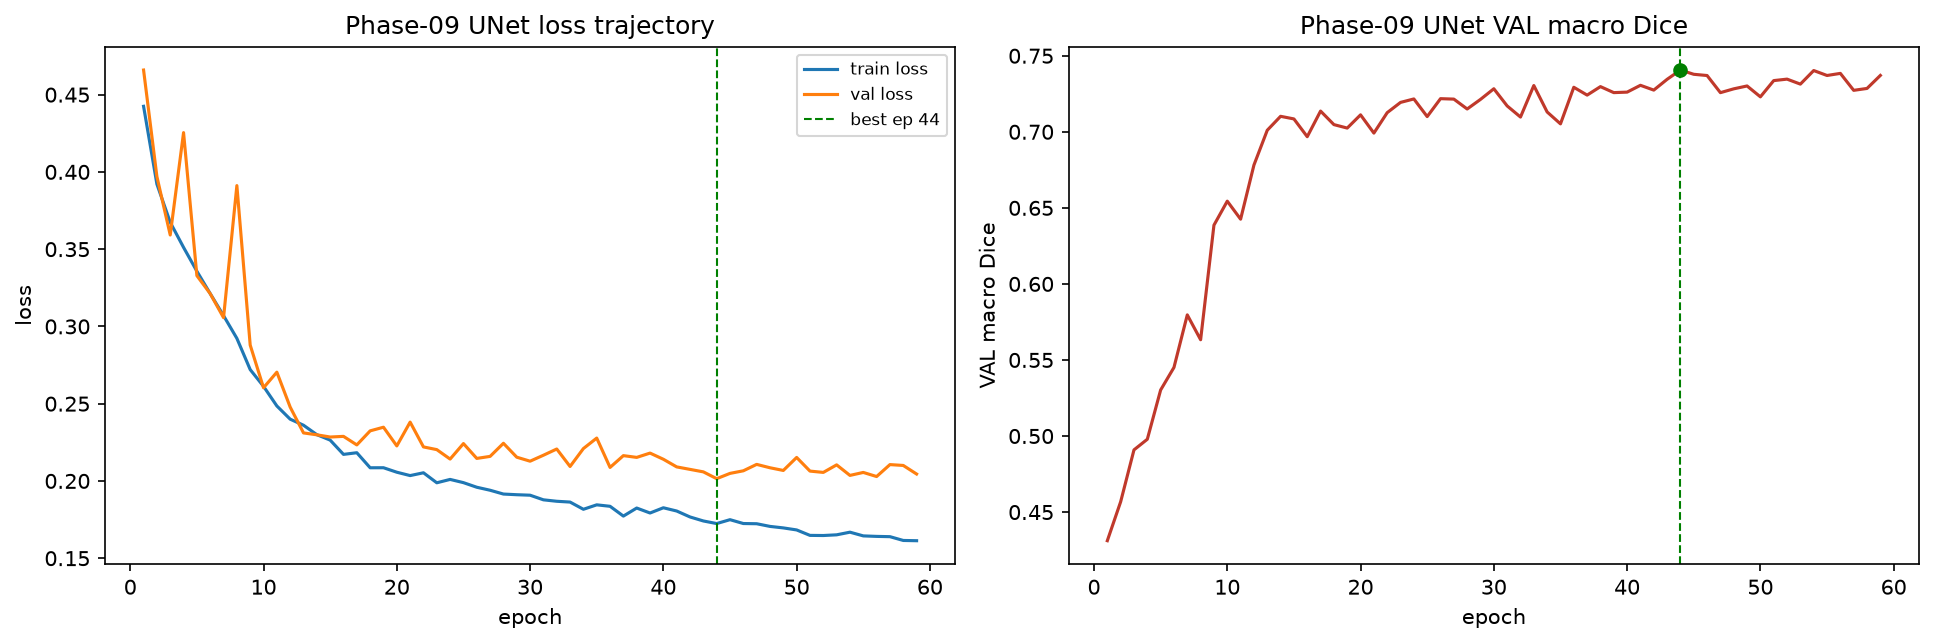

C:\Users\user\AppData\Local\Temp\ipykernel_43772\4071004266.py:79: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


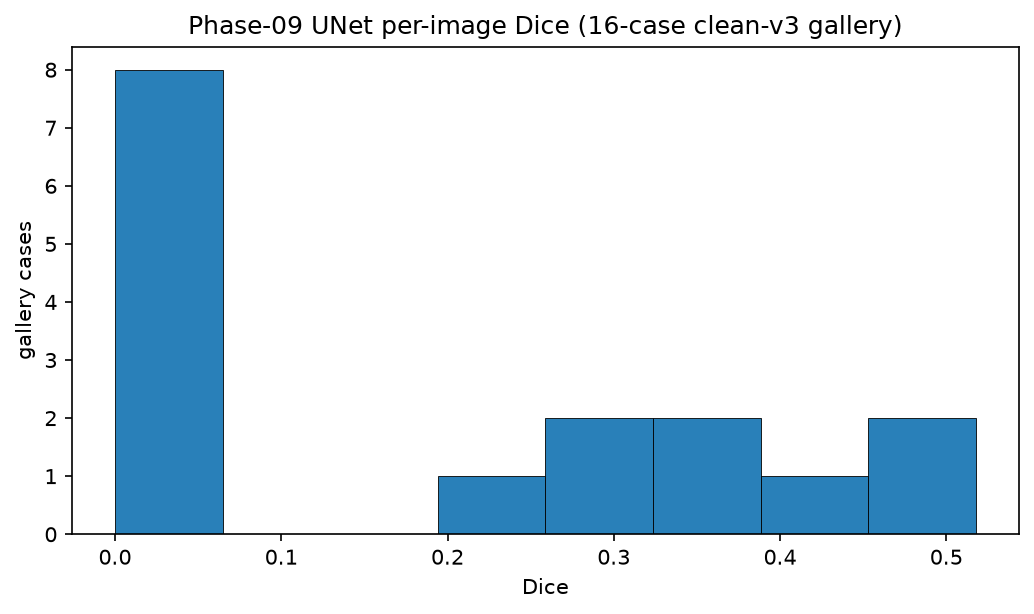

All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE
No training, no inference, no TEST access.


In [18]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

prov = [
    ('phase09_clean_v3_training_history.csv', _TAB / 'phase09_clean_v3_training_history.csv'),
    ('phase09_clean_v3_best_val_summary.csv', _TAB / 'phase09_clean_v3_best_val_summary.csv'),
    ('phase09_clean_v3_val_gallery_metrics.csv', _TAB / 'phase09_clean_v3_val_gallery_metrics.csv'),
]
_disp(_pd.DataFrame([{'artifact': n, 'sha256': _sha(p)[:16], 'exists': p.exists()} for n, p in prov]))

hist = _pd.read_csv(_TAB / 'phase09_clean_v3_training_history.csv')
best = hist.loc[hist['val_macro_dice'].idxmax()]
_disp(_pd.DataFrame([{
    'epochs': int(hist['epoch'].max()), 'best_epoch': int(best['epoch']),
    'val_macro_dice': float(best['val_macro_dice']), 'val_macro_iou': float(best['val_macro_iou']),
    'val_macro_precision': float(best['val_macro_precision']), 'val_macro_recall': float(best['val_macro_recall']),
    'train_loss': float(best['train_loss']), 'val_loss': float(best['val_loss']),
    'metric_domain': 'TRAINING_OPTIMIZATION', 'label': LBL,
}]).round(6))

avail = _pd.DataFrame([
    {'metric_family': 'Dice / IoU / precision / recall', 'status': 'YES',
     'source': 'phase09_clean_v3_training_history.csv (epoch aggregate)'},
    {'metric_family': 'per-image Dice / IoU distribution', 'status': 'YES (16-case gallery)',
     'source': 'phase09_clean_v3_val_gallery_metrics.csv'},
    {'metric_family': 'specificity / balanced accuracy / MCC / kappa', 'status': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS',
     'source': 'no per-pixel confusion persisted for the Phase-09 UNet'},
    {'metric_family': 'confusion matrix (raw / normalized)', 'status': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS',
     'source': 'safe replay covers UNet++ (GLOBAL arm), not the Phase-09 UNet'},
    {'metric_family': 'boundary HD95 / ASSD / surface Dice', 'status': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS',
     'source': 'no persisted masks; model identity mismatch'},
    {'metric_family': 'calibration Brier / ECE / reliability', 'status': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS',
     'source': 'no persisted probability maps; model identity mismatch'},
    {'metric_family': 'proposal / localizer metrics', 'status': 'NA',
     'source': 'not a localization task in Phase 09'},
])
_disp(avail)

fig, (ax1, ax2) = _plt.subplots(1, 2, figsize=(13, 4.4))
ax1.plot(hist['epoch'], hist['train_loss'], label='train loss')
ax1.plot(hist['epoch'], hist['val_loss'], label='val loss')
ax1.axvline(int(best['epoch']), color='green', ls='--', lw=1, label=f"best ep {int(best['epoch'])}")
ax1.set_xlabel('epoch'); ax1.set_ylabel('loss'); ax1.set_title('Phase-09 UNet loss trajectory'); ax1.legend(fontsize=8)
ax2.plot(hist['epoch'], hist['val_macro_dice'], color='#c0392b')
ax2.axvline(int(best['epoch']), color='green', ls='--', lw=1)
ax2.scatter([best['epoch']], [best['val_macro_dice']], color='green', zorder=5)
ax2.set_xlabel('epoch'); ax2.set_ylabel('VAL macro Dice'); ax2.set_title('Phase-09 UNet VAL macro Dice')
_plt.tight_layout(); _p = _FIG / 'phase09_loss_and_dice.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

gm = _pd.read_csv(_TAB / 'phase09_clean_v3_val_gallery_metrics.csv')
fig, ax = _plt.subplots(figsize=(7, 4.2))
ax.hist(gm['dice'].astype(float), bins=8, color='#2980b9', edgecolor='black', lw=0.4)
ax.set_xlabel('Dice'); ax.set_ylabel('gallery cases'); ax.set_title('Phase-09 UNet per-image Dice (16-case clean-v3 gallery)')
_plt.tight_layout(); _p = _FIG / 'phase09_gallery_dice_hist.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

print('All values above are', LBL)
print('No training, no inference, no TEST access.')